# Chapter 9 | Worked solutions

*Scaling Data, Compute, and Expert Capacity*

## Goal

Work through all 14 exercises, from counting training presentations to
designing a fair dense-versus-expert comparison. The first six build intuition
with hand calculations; Exercises 7-11 use small numerical investigations;
Exercises 12-14 extend the ideas. Every result uses the stated inputs. The
loss curve is synthetic, and the fixed expert weights illustrate routing
rather than trained specialization. The last exercise is a proposed protocol,
not a report of an experiment that has been run.

The written PDF contains the explanations, calculations, tables, and plot.
The notebook PDF also contains every code cell and saved result.

## Setup

Open this notebook inside `transformers-book`, install the packages in
`requirements.txt` plus `matplotlib` and `jupyterlab`, and run all cells in order.
The examples need only a CPU and do not download a model or dataset. Counts
refer to matrix entries and token presentations; they are not elapsed times.
Numerical checks use float64 with declared tolerances. Exact IDs, masks, and
integer counts are checked for equality. Small last-digit differences can
occur across environments.

In [1]:
from pathlib import Path
import sys

import numpy as np

working_directory = Path.cwd()
for repo_root in (working_directory, *working_directory.parents):
    model_path = (
        repo_root / "examples" / "ch09_scaling" / "model.py"
    )
    if model_path.is_file():
        sys.path.insert(0, str(repo_root))
        break
else:
    raise FileNotFoundError(
        "Open this notebook inside transformers-book."
    )

In [2]:
import platform
print("Python", platform.python_version())
print("NumPy", np.__version__)
from examples.ch09_scaling.model import (
    BILLION, allocation_sweep, training_flops, tokens_at_budget,
    route_top1, topk_gates, expert_branch,
)
from examples.ch09_scaling.run_examples import (
    teaching_weights, capacity_example, balance_diagnostic_example,
)

Python 3.12.14
NumPy 2.5.4


## Steps

For each exercise, first follow the calculation in words, then check it numerically.

## 1. Spend the same budget

A 12-billion-parameter dense model processes 300 billion token presentations.
The estimate is $C\approx6ND$. Both counts are raw counts, so both factors of
$10^9$ must be included:

$$
C\approx6(12\times10^9)(300\times10^9)=2.16\times10^{22}\text{ FLOPs}.
$$

The factor six approximates three matrix multiplications per linear map:
one forward multiplication and two backward multiplications, each costing
about two operations per weight per input row. Attention products and other
operations need separate accounting.

Doubling the number of weights doubles the approximate cost per presentation.
At a fixed budget we can afford half as many presentations:

$$
D\approx\frac{2.16\times10^{22}}{6(24\times10^9)}
=150\times10^9.
$$

Doubling both original counts means twice the work per token and twice as many
tokens. The estimate becomes four times larger, $8.64\times10^{22}$ FLOPs.

| Run | Parameters (billions) | Presentations (billions) | Estimated FLOPs |
| --- | --- | --- | --- |
| Original | 12 | 300 | $2.16\times10^{22}$ |
| Larger model, same budget | 24 | 150 | $2.16\times10^{22}$ |
| Double both original counts | 24 | 600 | $8.64\times10^{22}$ |

FLOPs measure work, whereas FLOPs per second measure a rate. Equal FLOP
estimates do not guarantee equal runtime on real hardware.

In [3]:
original_compute = training_flops(12 * BILLION, 300 * BILLION)
larger_tokens = tokens_at_budget(original_compute, 24 * BILLION)
double_both = training_flops(24 * BILLION, 600 * BILLION)
assert original_compute == 6 * 12 * 300 * BILLION**2
assert larger_tokens == 150 * BILLION
assert double_both == 4 * original_compute
print(f"Original compute: {original_compute:.3e} FLOPs")
print(f"Larger model: {larger_tokens / BILLION:g}B presentations")
print(f"Double both: {double_both:.3e} FLOPs")

Original compute: 2.160e+22 FLOPs
Larger model: 150B presentations
Double both: 8.640e+22 FLOPs


## 2. Count what the model sees

An epoch is one complete pass through a corpus. Corpus A contains 120 million
token positions and is read three times. Corpus B contains 360 million
positions and is read once. Both runs process 360 million presentations:

$$
D_A=3(120\times10^6)=360\times10^6,
\qquad D_B=1(360\times10^6)=360\times10^6.
$$

With the same dense model, both estimates equal
$6N(360\times10^6)=2.16\times10^9N$ FLOPs. The corpus position count differs,
even though the work estimate agrees. Neither count is vocabulary size: many
positions can contain the same token type.

The learning evidence need not agree. Corpus A presents its contexts three
times; Corpus B may introduce more varied contexts. Repetition can help learn
useful patterns, while more positions can also include irrelevant text or
duplicates. The counts alone do not tell us which model has lower held-out
loss. Compare on the same reserved text with the same tokenizer. Keep
duplicate documents in a single split so that training copies do not leak
into evaluation.

In [4]:
presentations_a = 120_000_000 * 3
presentations_b = 360_000_000 * 1
assert presentations_a == presentations_b
print("A presentations:", f"{presentations_a:,}")
print("B presentations:", f"{presentations_b:,}")
print("FLOPs per model parameter:", 6 * presentations_a)

A presentations: 360,000,000
B presentations: 360,000,000
FLOPs per model parameter: 2160000000


## 3. Trace a token

The input is $x=(1,0,0,0)$ and the expert probabilities are
$(0.1,0.6,0.2,0.1)$. These are probabilities over experts, not predictions
over vocabulary tokens. Assume all selected requests are accepted.

Switch chooses expert 2, keeps its original gate $0.6$, and computes

$$
y_{\rm Switch}=0.6(2,-1,0,3)=(1.2,-0.6,0,1.8),
$$

so the residual output is $x+y_{\rm Switch}=(2.2,-0.6,0,1.8)$.

For the selected-logit top-two rule, retain experts 2 and 3. Their original
probabilities sum to $0.8$. Dividing by that sum preserves their ratio while
making the retained gates sum to one:

$$
g_2=0.6/0.8=0.75,\qquad g_3=0.2/0.8=0.25.
$$

| Expert | Gate | Given output | Gated contribution |
| --- | --- | --- | --- |
| 2 | $0.75$ | $(2,-1,0,3)$ | $(1.5,-0.75,0,2.25)$ |
| 3 | $0.25$ | $(0,1,4,-1)$ | $(0,0.25,1,-0.25)$ |

The contributions sum to $y=(1.5,-0.5,1,2)$. Add the original input once to
obtain $(2.5,-0.5,1,2)$. Adding it separately to each expert output would
change the operation.

The denominator excludes experts 1 and 4 because only the selected pair is
renormalized. Equivalently, softmax acts on the two retained logits. This
rule differs from Switch: renormalizing a single retained logit gives gate
one. The helper below makes that distinction explicit. The expert outputs
here are given vectors, separate from the later fixed teaching bank.

In [5]:
probabilities = np.array([[0.1, 0.6, 0.2, 0.1]])
logits = np.log(probabilities)
x_hand = np.array([1., 0., 0., 0.])
expert2 = np.array([2., -1., 0., 3.])
expert3 = np.array([0., 1., 4., -1.])
switch_update = route_top1(logits, 1)[2][0] * expert2
ids2, gates2 = topk_gates(logits, 2)
np.testing.assert_array_equal(ids2, [[1, 2]])
np.testing.assert_allclose(gates2, [[.75, .25]], atol=1e-14)
two_update = gates2[0] @ np.stack([expert2, expert3])
np.testing.assert_allclose(two_update, [1.5, -.5, 1, 2])
print("Switch update / residual:", switch_update, x_hand + switch_update)
print("Top-two update / residual:", two_update, x_hand + two_update)
print("Renormalized top-one gate:", topk_gates(logits, 1)[1])

Switch update / residual: [ 1.2 -0.6  0.   1.8] [ 2.2 -0.6  0.   1.8]
Top-two update / residual: [ 1.5 -0.5  1.   2. ] [ 2.5 -0.5  1.   2. ]
Renormalized top-one gate: [[1.]]


## 4. Count a wider bank

Each expert uses a $6\times12$ up projection and a $12\times6$ down
projection. These are two bias-free matrices, so one expert has
$72+72=144$ weights. Four experts store $576$ weights. The router adds
$6\times4=24$, giving $600$ stored weights in this routed branch.

| Component or path | Weight count |
| --- | --- |
| One two-matrix expert | $2(6)(12)=144$ |
| Four experts | $4(144)=576$ |
| Router | $6(4)=24$ |
| Whole branch stored | $576+24=600$ |
| One accepted top-one token | $144+24=168$ |
| One token accepted by two experts | $2(144)+24=312$ |

The router scores all four choices once for either policy. The unselected
experts remain stored, and other rows in a batch may use them. Counts include
all entries in the matrices, including zero-valued entries. The formulas
assume two-matrix ReLU experts. For SwiGLU, each expert instead has three
matrices and $3dh$ weights. Softmax, activations, communication, and shared
attention layers add work beyond these parameter counts.

In [6]:
width, hidden, experts = 6, 12, 4
one_expert = 2 * width * hidden
router = width * experts
stored = experts * one_expert + router
used_top1 = one_expert + router
used_top2 = 2 * one_expert + router
assert (stored, used_top1, used_top2) == (600, 168, 312)
print("Stored / top-one use / top-two use:", stored, used_top1, used_top2)

Stored / top-one use / top-two use: 600 168 312


## 5. Separate demand from room

The average number of requests per expert is $T/E=8/4=2$. A capacity factor
of $1.5$ reserves three slots at each expert:

$$
K_{\rm cap}=\lceil1.5(8/4)\rceil=3.
$$

The request counts are $(1,5,1,1)$. Expert 2 admits rows 2, 3, and 4 in input
order. Rows 5 and 6 overflow. Each other expert accepts its single request,
so the accepted counts are $(1,3,1,1)$ and six rows are processed.

| Capacity per expert | Accepted rows | Overflow rows | Overflow fraction | Slot utilization |
| --- | --- | --- | --- | --- |
| 3 | 6 | 5, 6 | $2/8=25\%$ | $6/12=50\%$ |
| 5 | 8 | None | $0/8=0\%$ | $8/20=40\%$ |

The denominators answer different questions. Overflow divides rejected
requests by all requests. Utilization divides accepted assignments by
reserved slots. At capacity three, expert 2 is full while the other experts
have unused slots. The policy does not redirect rejected requests or lend
slots between experts. At capacity five all requests fit, but reserving more
slots lowers the utilization fraction. Overflow skips the expert update;
it does not erase a token from the sequence or its training target.

In [7]:
import math
assert math.ceil(1.5 * 8 / 4) == 3
for cap in (3, 5):
    record = capacity_example(cap)
    print(f"Capacity {cap}: accepted {record['processed_per_expert']}")
    print("  Overflow rows:", record["overflow_rows"])
    print(f"  Overflow {record['overflow_fraction']:.0%}; "
          f"slot utilization {record['slot_utilization']:.0%}")
assert capacity_example(3)["overflow_fraction"] == .25
assert capacity_example(5)["slot_utilization"] == .4

Capacity 3: accepted [1, 3, 1, 1]
  Overflow rows: [5, 6]
  Overflow 25%; slot utilization 50%
Capacity 5: accepted [1, 5, 1, 1]
  Overflow rows: []
  Overflow 0%; slot utilization 40%


## 6. Read a router diagnostic carefully

Equal logits give equal probabilities. Every row therefore has probabilities
$(1/4,1/4,1/4,1/4)$. Our tie rule picks the lowest expert ID, so all four rows
request expert 1. The hard request fractions and the average probabilities
are different:

$$
f=(1,0,0,0),\qquad P=(1/4,1/4,1/4,1/4),
\qquad b=4f^\top P=1.
$$

Capacity one admits row 1 and rejects rows 2, 3, and 4. Three of four
requests overflow, although three other experts remain empty.

For the second router, each of the four experts wins exactly once. Each
column contains one $0.7$ and three $0.1$ probabilities, so its mean is
$(0.7+3\cdot0.1)/4=1/4$. Now both $f$ and $P$ are uniform:

$$
b=4\left[4(1/4)(1/4)\right]=1.
$$

All four requests fit. Thus the same auxiliary value accompanies two very
different outcomes. The value 1 is a useful reference, not proof that hard
requests are balanced. Monitor request counts, accepted counts, and overflow
alongside the raw balance term. Its mean-probability part provides gradients
to the router during training; hard argmax counts are not differentiated.

In [8]:
diagnostics = balance_diagnostic_example()
for name, record in diagnostics.items():
    print(name)
    print("  Requests:", record["requests_per_expert"])
    print("  Mean probabilities:", record["mean_probability"])
    print("  Raw balance:", record["raw_balance_term"])
    print("  Accepted rows:", record["accepted_rows"])
    print(f"  Overflow: {record['overflow_fraction']:.0%}")
    np.testing.assert_allclose(record["raw_balance_term"], 1., atol=1e-14)
assert diagnostics["tied"]["accepted_rows"] == [1]
assert diagnostics["balanced"]["accepted_rows"] == [1, 2, 3, 4]

tied
  Requests: [4, 0, 0, 0]
  Mean probabilities: [0.25, 0.25, 0.25, 0.25]
  Raw balance: 1.0
  Accepted rows: [1]
  Overflow: 75%
balanced
  Requests: [1, 1, 1, 1]
  Mean probabilities: [0.25000000000000006, 0.25000000000000006, 0.24999999999999997, 0.25]
  Raw balance: 1.0
  Accepted rows: [1, 2, 3, 4]
  Overflow: 0%


## 7. Refine the sweep

Imagine choosing between a model with 10 billion parameters and
another with 13 billion. At the same training budget, the second
model spends more on every token and can therefore process fewer
tokens. The exercise asks whether the improvement in the chapter's
size penalty is large enough to offset the increase in its token
penalty. The chapter table tried sizes 5, 10, 20, 40, and 80 billion
and found the lowest loss at 10 billion. Now test more choices
between 10 and 20.

The notation $N_B=N/10^9$ and $D_B=D/10^9$ expresses the parameter
count and token presentations in billions. Substituting the raw
counts $N=N_B10^9$ and $D=D_B10^9$ into $C\approx 6ND$ gives
$C\approx 6\cdot10^{18}N_BD_B$. The same budget fixes their product.

$$
N_BD_B=\frac{2.4\cdot10^{22}}{6\cdot10^{18}}=4000,
\qquad D_B=\frac{4000}{N_B}.
$$

For each size, `allocation_sweep` solves for its token allocation
and evaluates the toy loss $1+0.4/\sqrt{N_B}+2/\sqrt{D_B}$.
Each returned row contains model size, token count, and loss,
in that order. We select the minimum by the loss in the third
field and use the full precision of the returned values. The
table formatting only changes how the numbers appear.

In [9]:
from examples.ch09_scaling.model import (
    BILLION, allocation_sweep, training_flops,
)

sweep_budget = 2.4e22
chapter_sizes = (5, 10, 20, 40, 80)
refined_sizes = (10, 12, 13, 14, 20)
chapter_rows = allocation_sweep(sweep_budget, chapter_sizes)
refined_rows = allocation_sweep(sweep_budget, refined_sizes)

chapter_best = min(chapter_rows, key=lambda row: row[2])
refined_best = min(refined_rows, key=lambda row: row[2])
assert chapter_best[0] == 10
assert refined_best[0] == 13

print("Model size (B)   Token count (B)      Toy loss")
for row in refined_rows:
    n_b, d_b, loss = row
    mark = "  <- best" if row == refined_best else ""
    print(f"{n_b:>14g}   {d_b:>15.6f}   {loss:>11.9f}{mark}")
print(f"Chapter table's best loss: {chapter_best[2]:.9f}")

Model size (B)   Token count (B)      Toy loss
            10        400.000000   1.226491106
            12        333.333333   1.225014565
            13        307.692308   1.224957582  <- best
            14        285.714286   1.225226092
            20        200.000000   1.230864075
Chapter table's best loss: 1.226491106


The best refined row gives 13 billion parameters, approximately
307.692308 billion token presentations, and a toy loss of about
1.224957582. The 10-billion row still has its previous loss of
about 1.226491106. We added the 12-, 13-, and 14-billion choices
between the original 10- and 20-billion rows, so the sweep could
now select an allocation that the chapter's table did not test.

We can see the tradeoff in the two loss terms. From 10 to 13
billion parameters, the size penalty falls from about 0.126491
to 0.110940. The token penalty rises from 0.100000 to about
0.114018. The decrease in the first term is larger than the
increase in the second, so the total falls.

To verify the budget, use the returned token allocation with
its full precision, rather than the rounded number printed in
the table. Multiplying each count by $10^9$ converts it to the
units expected by `training_flops`. The helper can use a
fractional token count for this calculation because solving
the budget equation is a continuous approximation. A real run
would choose a whole number of token presentations.

In [10]:
best_size_b, best_tokens_b, _ = refined_best
best_parameters = best_size_b * BILLION
best_tokens = best_tokens_b * BILLION
estimated_flops = training_flops(best_parameters, best_tokens)

np.testing.assert_allclose(
    estimated_flops, sweep_budget, rtol=1e-14, atol=0,
)

print(f"Parameters as a raw count: {best_parameters:,}")
print(f"Token presentations as a raw count: {best_tokens:,.4f}")
print(f"Estimated FLOPs: {estimated_flops:.9e}")

Parameters as a raw count: 13,000,000,000
Token presentations as a raw count: 307,692,307,692.3077
Estimated FLOPs: 2.400000000e+22


The check agrees at the scale of the budget, with relative
tolerance $10^{-14}$ and zero absolute tolerance. A budget of
$2.4\cdot10^{22}$ is too large for a useful comparison based on
a small absolute error. The relative tolerance compares the
discrepancy to the magnitude of the budget.

The chosen row minimizes the chapter's made-up loss over the
tested sizes. Its advantage comes from changing which sizes are
available at the same compute budget. Exercise 13 finds the
minimum of this same curve when any positive size is allowed.

The plot below shows the same synthetic curve, with the refined candidates
overlaid. The best sampled point at 13B is close to, but distinct from, the
continuous minimum near 12.65B. The companion panel explains the shape:
the model penalty falls while the token penalty rises at fixed compute.
These are calculated curves, not empirical training measurements.

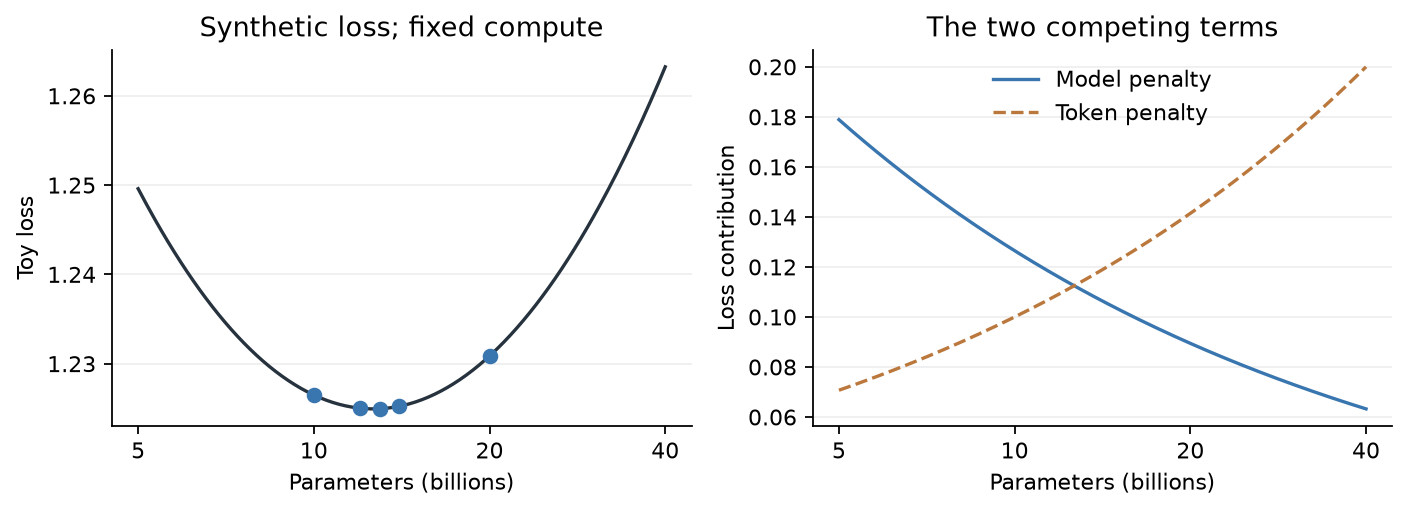

In [11]:
import io
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display

sizes = np.geomspace(5, 40, 250)
tokens = 4000 / sizes
model_term = .4 / np.sqrt(sizes)
data_term = 2 / np.sqrt(tokens)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.3))
axes[0].plot(sizes, 1 + model_term + data_term, color="#26323d")
axes[0].scatter([r[0] for r in refined_rows],
                [r[2] for r in refined_rows], color="#3976af", zorder=3)
axes[0].set(title="Synthetic loss; fixed compute", ylabel="Toy loss")
axes[1].plot(sizes, model_term, color="#3976af", label="Model penalty")
axes[1].plot(sizes, data_term, "--", color="#bb783d", label="Token penalty")
axes[1].set(title="The two competing terms", ylabel="Loss contribution")
axes[1].legend(frameon=False)
for ax in axes:
    ax.set_xscale("log", base=2)
    ax.set_xticks([5, 10, 20, 40], labels=[5, 10, 20, 40])
    ax.set_xlabel("Parameters (billions)")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=.2)
fig.tight_layout()
buffer = io.BytesIO()
fig.savefig(buffer, format="png", dpi=160, bbox_inches="tight")
display(Image(data=buffer.getvalue()))
plt.close(fig)

## 8. Check the score shift

A router looks at a row of scores, called **logits**, and requests
the expert with the largest score. For this token the four expert
probabilities are $(0.1,0.6,0.2,0.1)$. Take their natural logarithms
to build a single logit row. Applying softmax to those logs
exponentiates them back to the four probabilities, whose sum is
already one.

The shape $[1,4]$ means one token and four experts. Adding
a common constant $c$ to all four scores preserves their order.
In particular, the second score stays the largest. The output ID
is 1 because Python indices start at zero. The expert is Expert 2
in the chapter's one-based numbering.

The probabilities should also agree. To see why, write $s_i$
for the logit of expert $i$. The shift contributes the same
multiplicative factor $exp(c)$ to the numerator and denominator.

$$
\frac{\exp(s_i+c)}{\sum_j \exp(s_j+c)}
=\frac{\exp(c)\exp(s_i)}{\exp(c)\sum_j \exp(s_j)}
=\frac{\exp(s_i)}{\sum_j \exp(s_j)}.
$$

That factor cancels in exact arithmetic. In Python, exponentiating
a value near 1,000 directly would overflow in float64. The
chapter's softmax first subtracts the largest logit in the row,
leaving nonpositive inputs to the exponential and at least one
exponential of zero. The subtraction also cancels a common
shift in exact arithmetic. Small rounding differences may remain
because the additions and subtractions use finite precision.

In [12]:
from examples.ch09_scaling.model import route_top1

target_probabilities = np.array(
    [[0.1, 0.6, 0.2, 0.1]], dtype=np.float64
)
base_scores = np.log(target_probabilities)
shifted_scores = base_scores + 1_000
base_prob, base_ids, base_gate, base_accept = route_top1(
    base_scores, capacity=1
)
shifted_prob, shifted_ids, shifted_gate, shifted_accept = route_top1(
    shifted_scores, capacity=1
)

probability_atol = 1e-12
np.testing.assert_array_equal(base_ids, [1])
np.testing.assert_array_equal(shifted_ids, base_ids)
np.testing.assert_array_equal(base_accept, [True])
np.testing.assert_array_equal(shifted_accept, base_accept)
for actual, expected in (
    (base_prob, target_probabilities),
    (shifted_prob, base_prob),
    (base_gate, [0.6]),
    (shifted_gate, base_gate),
):
    np.testing.assert_allclose(
        actual, expected, rtol=0, atol=probability_atol
    )

In [13]:
with np.printoptions(precision=12):
    print("Original logits")
    print(base_scores)
    print("Shifted logits")
    print(shifted_scores)
    print("Original probabilities", base_prob)
    print("Shifted probabilities ", shifted_prob)
    print("Original ID, gate, acceptance", base_ids,
          base_gate, base_accept)
    print("Shifted ID, gate, acceptance ", shifted_ids,
          shifted_gate, shifted_accept)
prob_delta = np.abs(base_prob - shifted_prob).max()
gate_delta = np.abs(base_gate - shifted_gate).max()
print(f"Max probability difference {prob_delta:.3e}")
print(f"Max gate difference        {gate_delta:.3e}")

Original logits
[[-2.302585092994 -0.510825623766 -1.609437912434 -2.302585092994]]
Shifted logits
[[997.697414907006 999.489174376234 998.390562087566 997.697414907006]]
Original probabilities [[0.1 0.6 0.2 0.1]]
Shifted probabilities  [[0.1 0.6 0.2 0.1]]
Original ID, gate, acceptance [1] [0.6] [ True]
Shifted ID, gate, acceptance  [1] [0.6] [ True]
Max probability difference 8.743e-15
Max gate difference        6.550e-15


The selected ID is exactly the same in both runs. One request
fits within capacity one. The gate is the probability of the
selected expert, about $0.6$, so it agrees as well. The helper
keeps that probability as the gate after choosing one expert.
It does not rescale it to one. The code checks the IDs and
Boolean masks for exact equality and uses absolute tolerance
$10^{-12}$ with zero relative tolerance for float64
probabilities and gates. The last two lines show the rounding
differences before the arrays are formatted for display.

## 9. Move the capacity limit

Put score 2 in one column per row and leave all the other
scores at zero. Because 2 is strictly greater than zero,
every row has a unique winner. The eight rows request
experts with zero-based IDs $0,1,1,1,1,1,2,3$. Written with
the chapter's expert labels, the request counts are
$(1,5,1,1)$ for Experts 1 through 4.

Capacity is a separate limit on how many requests each expert
accepts. The teaching router gathers the requests for one
expert in original row order and keeps the first
`capacity` of them. Expert 2 receives rows 2 through 6, so
at capacity 2 it accepts rows 2 and 3. The other experts receive
one request each and can accept all of theirs. These row
numbers start at one to match the book.

In [14]:
winning_ids = np.array([0, 1, 1, 1, 1, 1, 2, 3])
num_rows, num_experts = 8, 4
capacity_scores = np.zeros((num_rows, num_experts))
capacity_scores[np.arange(num_rows), winning_ids] = 2

print("Score matrix, one row per token")
print(capacity_scores)
print("Requested expert labels", (winning_ids + 1).tolist())
request_counts = np.bincount(winning_ids, minlength=num_experts)
print("Requests per expert    ", request_counts.tolist())

Score matrix, one row per token
[[2. 0. 0. 0.]
 [0. 2. 0. 0.]
 [0. 2. 0. 0.]
 [0. 2. 0. 0.]
 [0. 2. 0. 0.]
 [0. 2. 0. 0.]
 [0. 0. 2. 0.]
 [0. 0. 0. 2.]]
Requested expert labels [1, 2, 2, 2, 2, 2, 3, 4]
Requests per expert     [1, 5, 1, 1]


For each capacity, use the Boolean acceptance mask to select
the IDs of accepted rows. Count those IDs with `np.bincount`.
Setting `minlength=4` keeps one slot per expert even if an
expert accepted no rows. To find overflow rows, locate
the false entries in the mask and add one to the resulting
indices. A row that overflows still has a selected ID.

In [15]:
expected_overflow = {2: [4, 5, 6], 3: [5, 6], 5: []}

for capacity in (2, 3, 5):
    _, requested_ids, _, accepted_rows = route_top1(
        capacity_scores, capacity=capacity
    )
    accepted_counts = np.bincount(
        requested_ids[accepted_rows], minlength=num_experts
    )
    overflow_rows = np.flatnonzero(~accepted_rows) + 1
    np.testing.assert_array_equal(requested_ids, winning_ids)
    np.testing.assert_array_equal(
        accepted_counts, np.minimum(request_counts, capacity)
    )
    np.testing.assert_array_equal(
        overflow_rows, expected_overflow[capacity]
    )
    print(f"Capacity {capacity}")
    print("  Accepted per expert", accepted_counts.tolist())
    print("  Total accepted     ", int(accepted_rows.sum()))
    print("  Overflow rows      ", overflow_rows.tolist())

Capacity 2
  Accepted per expert [1, 2, 1, 1]
  Total accepted      5
  Overflow rows       [4, 5, 6]
Capacity 3
  Accepted per expert [1, 3, 1, 1]
  Total accepted      6
  Overflow rows       [5, 6]
Capacity 5
  Accepted per expert [1, 5, 1, 1]
  Total accepted      8
  Overflow rows       []


At capacity 3, the extra slot at Expert 2 admits row 4,
leaving rows 5 and 6 in overflow. At capacity 5 all eight
requests fit. In all three runs the three other experts
accept one row apiece.

Empty slots elsewhere cannot take Expert 2's extra requests.
For example, at capacity 2 there are eight slots across the
four experts, but Expert 2 has only two of them. Each of the
other three experts has one unused slot, which this router
cannot give to Expert 2. There is no retry with another expert
after overflow. Changing capacity therefore changes which
requests are executed while leaving the score matrix and the
requested expert for each row the same.

## 10. Check the residual

The chapter's `teaching_weights()` gives the router matrix and
both expert projections. The input $x=(1,0,0,0)$ is a row of
shape $[1,4]$. Multiplying it by the router matrix selects
the matrix's first row, because the first input coordinate
is 1 and all the rest are zero. That row contains the same
logarithms as in Exercise 8, so the router requests Expert 2
with gate $0.6$.

At capacity one, the expert's up projection copies the input's
first coordinate into its first hidden unit. The remaining
hidden coordinates are zero. ReLU preserves this vector by
replacing only negative entries with zero. The down projection
uses the first row of the expert's down matrix to produce
$(2,-1,0,3)$. Multiplying by the gate gives the branch update.

$$
0.6(2,-1,0,3)=(1.2,-0.6,0,1.8).
$$

Adding the original input then gives $(2.2,-0.6,0,1.8)$.
At capacity zero, the route still requests Expert 2 and the
gate still records $0.6$. The acceptance mask is false. The
branch helper starts with a zero update and fills it only
for accepted rows. So this row keeps its zero update and the
residual addition returns $(1,0,0,0)$.

In [16]:
from examples.ch09_scaling.model import expert_branch
from examples.ch09_scaling.run_examples import teaching_weights

bypass_router, bypass_up, bypass_down = teaching_weights()
bypass_input = np.array([[1., 0., 0., 0.]], dtype=np.float64)
bypass_scores = bypass_input @ bypass_router

print("Router, up, and down shapes",
      bypass_router.shape, bypass_up.shape, bypass_down.shape)
with np.printoptions(precision=9):
    print("Input row          ", bypass_input)
    print("Computed router row", bypass_scores)
    print("First row of router", bypass_router[:1])
np.testing.assert_array_equal(bypass_scores, bypass_router[:1])

Router, up, and down shapes (4, 4) (4, 4, 8) (4, 8, 4)
Input row           [[1. 0. 0. 0.]]
Computed router row [[-2.302585093 -0.510825624 -1.609437912 -2.302585093]]
First row of router [[-2.302585093 -0.510825624 -1.609437912 -2.302585093]]


In [17]:
expected_branch = {1: [[1.2, -0.6, 0., 1.8]], 0: [[0., 0., 0., 0.]]}
expected_residual = {1: [[2.2, -0.6, 0., 1.8]], 0: [[1., 0., 0., 0.]]}

for capacity in (1, 0):
    _, ids, gates, accepted = route_top1(
        bypass_scores, capacity=capacity
    )
    update = expert_branch(
        bypass_input, ids, gates, accepted, bypass_up, bypass_down
    )
    residual = bypass_input + update

    np.testing.assert_array_equal(ids, [1])
    np.testing.assert_array_equal(accepted, [capacity == 1])
    np.testing.assert_allclose(gates, [0.6], rtol=0, atol=1e-12)
    np.testing.assert_allclose(
        update, expected_branch[capacity], rtol=0, atol=1e-12
    )
    np.testing.assert_allclose(
        residual, expected_residual[capacity], rtol=0, atol=1e-12
    )
    if capacity == 0:
        np.testing.assert_array_equal(residual, bypass_input)

    print(f"Capacity {capacity}")
    print("  Selected ID, gate, accepted", ids, gates, accepted)
    print("  Expert branch update       ", update)
    print("  After adding input         ", residual)

Capacity 1
  Selected ID, gate, accepted [1] [0.6] [ True]
  Expert branch update        [[ 1.2 -0.6  0.   1.8]]
  After adding input          [[ 2.2 -0.6  0.   1.8]]
Capacity 0
  Selected ID, gate, accepted [1] [0.6] [False]
  Expert branch update        [[0. 0. 0. 0.]]
  After adding input          [[1. 0. 0. 0.]]


The branch update and residual output answer different
questions. At capacity zero, the expert branch changes no
features. The token's input still travels through the residual
path, which is why its output is the original vector. The
acceptance mask is the part of the router result that changes
between these runs. The next exercise compares requests and
acceptances for a whole batch.

## 11. Compare requests with probabilities

Suppose five of eight tokens ask for expert 2. That expert can
receive three of them at capacity three or two of them at capacity
two. We still want to describe how many tokens asked for it
and how strongly the router favored it. Those are two different
summaries of the same router scores.

A row of the identity matrix contains a single 1 and three zeros.
Multiplying it by the router matrix selects the row at the
position of that 1. The index list `[1, 0, 0, 0, 0, 0, 2, 3]`
selects router row 0 five times and each of the other rows once.
The teaching weights are logarithms of probability vectors.
Exponentiating and normalizing a selected row recovers its
original probabilities because they already sum to one.

For each expert $i$, compute the **request fraction** $f_i$ by
counting how many rows chose it and dividing by eight. The
**mean probability** $P_i$ averages column $i$ over all eight
rows, including rows that chose another expert. For example,
five rows give expert 2 probability $0.6$ and the three others
give it $0.2$ each, so $P_2=(5\cdot0.6+3\cdot0.2)/8=0.45$.
Its request fraction is $f_2=5/8=0.625$.

In [18]:
from examples.ch09_scaling.model import route_top1
from examples.ch09_scaling.run_examples import teaching_weights

balance_x = np.eye(4, dtype=np.float64)[[1, 0, 0, 0, 0, 0, 2, 3]]
balance_router, _, _ = teaching_weights()
balance_scores = balance_x @ balance_router
print("Input rows (one feature active per row)")
print(balance_x)

balance_probs, balance_ids, balance_gates, mask3 = route_top1(
    balance_scores, capacity=3
)
print("Router probability rows")
print(balance_probs)
print("Requests in one-based expert numbering:", balance_ids + 1)

Input rows (one feature active per row)
[[0. 1. 0. 0.]
 [1. 0. 0. 0.]
 [1. 0. 0. 0.]
 [1. 0. 0. 0.]
 [1. 0. 0. 0.]
 [1. 0. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
Router probability rows
[[0.6 0.2 0.1 0.1]
 [0.1 0.6 0.2 0.1]
 [0.1 0.6 0.2 0.1]
 [0.1 0.6 0.2 0.1]
 [0.1 0.6 0.2 0.1]
 [0.1 0.6 0.2 0.1]
 [0.1 0.2 0.6 0.1]
 [0.1 0.2 0.1 0.6]]
Requests in one-based expert numbering: [1 2 2 2 2 2 3 4]


NumPy counts the returned expert IDs from 0 through 3. The printed
requests add one so that they use the book's expert numbers.
Use `np.bincount` on the full array of IDs for the request counts
and on just the IDs with a true mask entry for accepted counts.
Setting `minlength=4` keeps a column even if it gets no rows.
Use `mean(axis=0)` to average the probability rows while
preserving one result per expert.

The chapter's raw balance term multiplies the two summaries
expert by expert and adds the contributions, then multiplies
by the number of experts $E=4$. Here the four products are
$0.0203125$, $0.28125$, $0.028125$, and $0.0203125$.

$$
b=E\sum_{i=1}^{E} f_i P_i
=4(0.0203125+0.28125+0.028125+0.0203125)
=1.4.
$$

Expert 2 contributes most because it has both the largest
fraction of requests and the largest mean probability.
Multiplying $b$ by a training coefficient would give its
weighted contribution to the training loss. We report $b$
itself here. Repeat the calculation for capacity two, then
compare the returned arrays. Use float64 with an absolute
tolerance of $10^{-12}$ and zero relative tolerance for the
probability calculations. Check integer counts and masks exactly.

In [19]:
probability2, ids2, gates2, mask2 = route_top1(
    balance_scores, capacity=2
)
np.testing.assert_array_equal(balance_ids, ids2)
np.testing.assert_allclose(
    balance_probs, probability2, atol=1e-12, rtol=0
)
np.testing.assert_allclose(
    balance_gates, gates2, atol=1e-12, rtol=0
)

for cap, probs, ids, accepted in (
    (3, balance_probs, balance_ids, mask3),
    (2, probability2, ids2, mask2),
):
    expert_count = probs.shape[1]
    requests = np.bincount(ids, minlength=expert_count)
    processed = np.bincount(ids[accepted], minlength=expert_count)
    f = requests / len(ids)
    P = probs.mean(axis=0)
    raw_balance = expert_count * (f @ P)
    overflow_rows = np.flatnonzero(~accepted) + 1

    np.testing.assert_array_equal(requests, [1, 5, 1, 1])
    np.testing.assert_array_equal(processed, [1, cap, 1, 1])
    np.testing.assert_allclose(
        f, [1/8, 5/8, 1/8, 1/8], atol=1e-12, rtol=0
    )
    np.testing.assert_allclose(
        P, [0.1625, 0.45, 0.225, 0.1625], atol=1e-12, rtol=0
    )
    np.testing.assert_allclose(raw_balance, 1.4, atol=1e-12, rtol=0)

    print(f"Capacity {cap}")
    print("  Requested / expert", requests.tolist())
    print("  Accepted / expert ", processed.tolist())
    print("  Accepted total    ", accepted.sum())
    print("  Overflow rows     ", overflow_rows.tolist())
    print("  f                 ", np.round(f, 4))
    print("  P                 ", np.round(P, 4))
    print(f"  Raw balance term   {raw_balance:.6f}")

Capacity 3
  Requested / expert [1, 5, 1, 1]
  Accepted / expert  [1, 3, 1, 1]
  Accepted total     6
  Overflow rows      [5, 6]
  f                  [0.125 0.625 0.125 0.125]
  P                  [0.1625 0.45   0.225  0.1625]
  Raw balance term   1.400000
Capacity 2
  Requested / expert [1, 5, 1, 1]
  Accepted / expert  [1, 2, 1, 1]
  Accepted total     5
  Overflow rows      [4, 5, 6]
  f                  [0.125 0.625 0.125 0.125]
  P                  [0.1625 0.45   0.225  0.1625]
  Raw balance term   1.400000


Capacity three accepts rows 2, 3, and 4 for expert 2. With
capacity two, row 4 also overflows. The other experts each
process their single request in both runs, so total acceptance
changes from six rows to five. The probabilities, selected IDs,
gates, $f$, $P$, and $b$ agree because the router scores are
the same and capacity is applied after the requests are made.
A gate is returned even for a rejected request. The expert
branch uses the acceptance mask to decide whether to apply it.

If we formed $f$ from processed rows, changing capacity would
change our estimate of demand even with the same input and
weights. Dividing the processed counts by eight at capacity
three would also give fractions that sum to $6/8$. The
chapter's definition counts every request before filtering,
so its fractions sum to one at both capacities.

## 12. Track two devices (optional)

All eight input rows start on A. Expert 2 receives five requests, but only
rows 2, 3, and 4 fit its capacity of three. First determine acceptance;
then count which accepted assignments are remote.

| Expert | Device | Requested rows | Accepted rows | Overflow rows |
| --- | --- | --- | --- | --- |
| 1 | A | 1 | 1 | None |
| 2 | B | 2, 3, 4, 5, 6 | 2, 3, 4 | 5, 6 |
| 3 | A | 7 | 7 | None |
| 4 | B | 8 | 8 | None |

A processes two local assignments, and B processes four remote assignments.
Each remote assignment sends one width-1,024 input vector and returns one
width-1,024 output vector. At two bytes per coordinate, each vector is
$1024\times2=2048$ bytes. Thus

$$
\text{payload}=4\text{ assignments}\times2\text{ directions}
\times1024\times2\text{ bytes}=16384\text{ bytes}=16\text{ KiB}.
$$

Dispatch accounts for 8,192 bytes and return for another 8,192 bytes. The
two rejected rows remain on A and receive zero expert updates. This count
assumes admission occurs before transfer and counts forward vector payload
only. Metadata, protocol overhead, padding, and backward traffic are outside
the question. If two selected experts for one token were remote, both
assignments would count. Token count and assignment count need not agree.

In [20]:
requests = np.array([0, 1, 1, 1, 1, 1, 2, 3])
traffic_scores = np.zeros((8, 4))
traffic_scores[np.arange(8), requests] = 2
_, ids, _, accepted = route_top1(traffic_scores, 3)
on_device_b = np.isin(ids, [1, 3])
remote = int((accepted & on_device_b).sum())
local = int((accepted & ~on_device_b).sum())
payload = remote * 1024 * 2 * 2
assert (local, remote, payload) == (2, 4, 16384)
print("Accepted assignments on A / B:", local, remote)
print("Forward dispatch plus return:", payload, "bytes")

Accepted assignments on A / B: 2 4
Forward dispatch plus return: 16384 bytes


## 13. Find the best continuous allocation (optional)

The 13-billion result in Exercise 7 came from a short list of
sizes. Suppose we can choose any positive model size and can use
the corresponding token count as a real number. This gives a
continuous problem. At first, the budget fixes
$Q=N_BD_B=4000$. The token count must be $D_B=Q/N_B$.

Write $z=\sqrt{N_B}>0$. Then $N_B=z^2$ and
$\sqrt{D_B}=\sqrt{Q}/z$. The positive square root is important
because $z$ represents the square root of a positive count.
After substitution, the two penalties and the floor give

$$
\ell_{\mathrm{toy}}
=1+\frac{0.4}{z}+\frac{2z}{\sqrt{Q}}
=1+\frac{a}{z}+bz,
\qquad a=0.4,\quad b=\frac{2}{\sqrt{Q}}.
$$

As the model grows, $a/z$ falls and $bz$ rises. Their product
$(a/z)(bz)=ab$ stays fixed. The arithmetic–geometric mean
inequality says the sum of two positive numbers is at least
twice the square root of their product. We can see it here by
writing the excess above that lower bound as a square.

$$
\frac{a}{z}+bz-2\sqrt{ab}
=\left(\sqrt{a/z}-\sqrt{bz}\right)^2\geq 0.
$$

The lower bound is attained when the square is zero. This
requires $a/z=bz$, so **the two penalties are equal at the
minimum**. Since $a,b>0$, exactly one positive $z$ satisfies
that condition. Solving for $z^2$ then gives the size and token
count in billions.

$$
N_B^*=z^2=\frac{a}{b}=0.2\sqrt{Q},
\qquad
D_B^*=\frac{Q}{N_B^*}=5\sqrt{Q}.
$$

At $Q=4000$, these counts are approximately 12.649111 billion
parameters and 316.227766 billion token presentations. Each
penalty is about 0.112468265, so the total including the floor
is about 1.224936530.

The compute budget is proportional to $Q$ because
$C\approx 6\cdot10^{18}Q$. Quadrupling $C$ from $2.4\cdot10^{22}$
to $9.6\cdot10^{22}$ makes $Q$ four times larger. Both optimal
counts are proportional to $\sqrt{Q}$, so both double. The
new continuous optimum is about 25.298221 billion parameters
and 632.455532 billion token presentations. The ratio
$D_B^*/N_B^*=25$ is constant in this example.

Check both budgets on a grid from 5.0 to 40.0 billion, in steps of 0.1.
Generate integer tenths and divide by 10 to include both endpoints without
accumulating floating-point step errors. Compare the two penalties and
inspect neighboring losses before rounding.

In [21]:
fine_sizes = [tenths / 10 for tenths in range(50, 401)]
assert len(fine_sizes) == 351
assert (fine_sizes[0], fine_sizes[-1]) == (5.0, 40.0)

continuous_sizes = []
expected_grid_sizes = (12.6, 25.3)

def report_allocation(factor, expected_size):
    budget = factor * sweep_budget
    q = budget / (6 * BILLION**2)
    n_star = 0.2 * np.sqrt(q)
    d_star = q / n_star
    size_penalty = 0.4 / np.sqrt(n_star)
    token_penalty = 2 / np.sqrt(d_star)
    loss_star = 1 + size_penalty + token_penalty
    continuous_sizes.append((n_star, d_star))

    np.testing.assert_allclose(
        size_penalty, token_penalty, rtol=1e-14, atol=0,
    )

    fine_rows = allocation_sweep(budget, fine_sizes)
    best_index = min(
        range(len(fine_rows)), key=lambda i: fine_rows[i][2]
    )
    best_size, best_data, best_loss = fine_rows[best_index]
    assert best_size == expected_size
    np.testing.assert_allclose(
        best_size * best_data, q, rtol=1e-14, atol=0,
    )
    gap = best_loss - loss_star
    assert gap >= 0

    print(f"Budget {budget:.1e} FLOPs (Q={q:g})")
    print(f"Continuous N_B={n_star:.9f}, D_B={d_star:.9f}")
    print(f"Continuous loss={loss_star:.12f}")
    print("      N_B          D_B         Grid loss")
    for i in range(best_index - 1, best_index + 2):
        n_b, d_b, loss = fine_rows[i]
        mark = "  <- best" if i == best_index else ""
        print(f"    {n_b:5.1f}    {d_b:11.6f}    {loss:.12f}{mark}")
    print(f"Best grid loss minus continuous loss: {gap:.3e}")



At the original budget, compare the continuous optimum with its nearest grid points.

In [22]:
report_allocation(1, 12.6)

Budget 2.4e+22 FLOPs (Q=4000)
Continuous N_B=12.649110641, D_B=316.227766017
Continuous loss=1.224936530076
      N_B          D_B         Grid loss
     12.5     320.000000    1.224940483865
     12.6     317.460317    1.224936955567  <- best
     12.7     314.960630    1.224936983349
Best grid loss minus continuous loss: 4.255e-07


Now quadruple the budget and check whether both continuous counts double.

In [23]:
report_allocation(4, 25.3)
np.testing.assert_allclose(
    continuous_sizes[1], 2 * np.asarray(continuous_sizes[0]),
    rtol=1e-14, atol=0,
)

Budget 9.6e+22 FLOPs (Q=16000)
Continuous N_B=25.298221281, D_B=632.455532034
Continuous loss=1.159054145753
      N_B          D_B         Grid loss
     25.2     634.920635    1.159054446621
     25.3     632.411067    1.159054145852  <- best
     25.4     629.921260    1.159054466266
Best grid loss minus continuous loss: 9.828e-11


At the original budget the grid winner is 12.6 billion parameters and
317.460317 billion token presentations. Sizes 12.6 and 12.7 bracket the
continuous optimum of 12.649111. Their losses differ by only about
$2.78\cdot10^{-8}$, so compare the returned values before rounding.

At four times the budget the grid winner is 25.3 billion parameters and
632.411067 billion presentations. Its loss exceeds the continuous minimum
by only about $9.83\cdot10^{-11}$. The continuous counts double exactly;
the grid winners need not. Twice 12.6 is 25.2, but 25.3 is better on the
larger-budget grid.

The equal-penalty rule and 25-to-1 ratio follow from this particular toy
loss and its coefficients. For real training, measure a loss surface on
held-out text and estimate compute for the models being compared.

## 14. Plan a fair comparison (optional)

We want to compare held-out next-token loss at a common approximate training
compute budget. We will also report parameter storage, overflow, and measured
generation time. This is an experimental plan; no winning model is assumed.

Use four causal decoder blocks of width $d=256$, four attention heads, and
context length 256. Keep attention, positional representation, normalization,
residual paths, embeddings, and vocabulary projection identical. Change the
feed-forward branch in every block. Choose a dense two-matrix ReLU branch
of hidden width 1,024, or eight two-matrix ReLU experts of width 1,020 with
a bias-free router. These widths match matrix-weight use for an accepted
top-one token while allowing different total storage.

| Quantity per block | Dense branch | Routed branch |
| --- | --- | --- |
| One expert or dense network | $2(256)(1024)=524288$ | $2(256)(1020)=522240$ |
| Router | 0 | $256(8)=2048$ |
| Stored branch weights | $524288$ | $8(522240)+2048=4179968$ |
| Weights used for an accepted token | $524288$ | $522240+2048=524288$ |
| Weights used for an overflow token | Not applicable | $2048$ |

Freeze a deduplicated corpus and record a manifest of document IDs. Assign
groups of duplicate or near-duplicate documents to one split, using a fixed
80/10/10 split by group. Train an 8,192-entry tokenizer on the training split
only. Both models use the same next-token windows, document boundaries, and
ignored padding labels. Use five paired seeds, 101-105: copy the shared initial
tensors within each pair and use the same training batch order. Each run gets
a fresh AdamW optimizer with betas $(0.9,0.999)$, weight decay $0.01$, peak
learning rate $3\times10^{-4}$, 5% warmup, and cosine decay indexed by the
fraction of the training budget spent. Keep the held-out test set untouched
until the evaluation protocol and hyperparameters are fixed.

Use Switch-style top-one routing and capacity
$\lceil1.25T/8\rceil$ for $T$ valid input rows in each routing group. Fix the
grouping and acceptance order. Overflow skips the expert update but keeps
the residual representation and next-token supervision. Add the raw balance
term with coefficient $0.01$ during training. Validation and test loss should
report the next-token objective separately from the auxiliary term.

Let $T_\ell$ count valid rows and $A_\ell$ count accepted requests at layer
$\ell$ in one batch. When the kernels process only those rows, estimate the
branch's forward-plus-backward matrix work as

$$
C_{\rm dense}\approx6\sum_\ell T_\ell(524288),
$$

$$
C_{\rm routed}\approx6\sum_\ell
\left[T_\ell(2048)+A_\ell(522240)\right].
$$

Add the shared attention projections, attention products, and vocabulary
projection using actual batch shapes. If a kernel multiplies padded rows or
reserved slots, charge those executed rows too. Record routing, elementwise
operations, and optimizer overhead separately. Stop after the first update
that reaches a common approximate budget, for example $10^{14}$ FLOPs, and
report the realized total and final-batch overshoot. Also record updates and
presentations: equal compute can allow different token counts when requests
overflow. Neither active-parameter counts nor this arithmetic estimate
establish equal runtime.

Evaluate the final checkpoint from each run. Sum negative log probabilities
over valid held-out labels and divide by their total count, giving nats per
token. Aggregate counts across batches before dividing, rather than averaging
batch means equally. Report each seed's loss and the mean and spread across
the paired runs. Compute overflow as rejected requests divided by all valid
requests, both overall and per layer, separately for training and evaluation.
Also inspect request counts, mean probabilities, accepted counts, and slot
utilization. One token can make a request in each routed layer, so this
denominator counts requests, not distinct sequence positions.

For generation timing, use the same accelerator, precision, software,
16 prompts of length 128, and 64 generated tokens per prompt. Fix greedy
decoding, the KV-cache procedure, and the routing capacity policy. Warm up,
synchronize the accelerator around timed intervals, alternate model order,
and report median times over repeated runs. Include prompt processing in
end-to-end time. Also report prefill through the first token selection and
the remaining 63 cached decoding steps separately. Record peak memory and,
if experts are distributed, the placement and communication payload. This
distinguishes quality at the selected training budget from the cost of
serving the resulting models.

## Checks

The notebook checks the budget identities, both gate rules, exact accepted
rows, capacity-dependent overflow, and the refined versus continuous optima.
Exercises 5 and 6 demonstrate why slot utilization and the auxiliary balance
term must be interpreted alongside their underlying counts. The synthetic
loss optimum and its 25-to-1 token ratio belong to the chosen teaching
function; neither is a universal recommendation for real training.

## Next Steps

Change one assumption at a time: the model-size grid, the expert capacity,
or the router logits. Predict the affected outputs before rerunning. For a
real scaling study, replace the synthetic loss with comparable held-out
measurements and fit only within a justified experimental range. For real
MoE systems, measure executed work, communication, and elapsed time.

The chapter's primary references include
[Chinchilla](https://arxiv.org/abs/2203.15556),
[Switch Transformers](https://www.jmlr.org/papers/v23/21-0998.html), and
[Mixtral](https://arxiv.org/abs/2401.04088). The exact calculations here are
reproducible from the companion code and the inputs declared in each exercise.